# Lab 5: Put Uncertainty Into Your Project

---

## What this lab is

The last lab is about **your** project. You take the one number your project is built around and turn it into something a decision maker can trust: a range, a back-test, a scenario comparison and a figure for your paper. Everything you produce here can go straight into the Overleaf paper and the slides due on **6 December**.

* **Part A. Your key quantity.** Load it as a tidy table.
* **Part B. Back-test.** Hide the last years, project them with two models, count how often the truth falls inside the 90% band.
* **Part C. A range by simulation.** Pick the two most uncertain inputs of your pipeline, simulate, and find which matters most.
* **Part D. Scenarios.** At least two, compared with the interval width.
* **Part E. [OPTIONAL] One LLM-extracted variable**, evaluated as in Lab 5.
* **Part F. Communicate.** One fan chart and one paragraph for the paper.

## Conventions

* Same as before: **[QUAL]** 2-4 sentences, **[QUANT]** a number plus one sentence.
* If your project data are not ready, set `USE_DEMO = True`: the notebook runs on a demo series (synthetic steel-sector emissions) so you can build the code now and switch later. **Graded answers must use your project data.**
* Run **Kernel -> Restart & Run All** before submitting.

## Submission

Work in your **project group**. Push this notebook to your **project repository** in a folder `labs/`, and send the repo URL by email as before (1 email per group).

1. Full name: Victor Henz  Student ID: B00817998
2. Full name: Edgar Gusching  Student ID: B00822088
3. Full name: Marius Rang  Student ID: B00821794
4. Full name: Ylias Guetari  Student ID: B00824832

**Project role (consultant / data scientist / risk analyst):** Consultant (sustainability consultant)
**Key quantity (one sentence, with unit):** RWE's operating wind + solar capacity (equity share, GW), rebuilt year by year from the GEM Global Integrated Power Tracker (September 2026 V2), and its 2030 value, which we turn into the capacity-factor-adjusted replacement ratio against the coal RWE has committed to close by 2030.
**Repo URL:** https://github.com/mariusrang/rwe-coal-exit-climate-risks

## Setup (given)

In [1]:
from pathlib import Path
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

pd.set_option("display.float_format", "{:,.2f}".format)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25})
SEED = 42
rng = np.random.default_rng(SEED)

USE_DEMO = False   # set to False once your project data load below


def demo_series():
    # Synthetic sector emissions (MtCO2), 2005-2024: growth that slows down, plus noise.
    years = np.arange(2005, 2025)
    t = years - 2005
    trend = 900 + 70 * t - 1.9 * t**2
    noise = np.random.default_rng(7).normal(0, 35, len(t))
    return pd.DataFrame({"year": years, "value": trend + noise})

---
# PART A. Your key quantity

**Goal.** Create `series`: a DataFrame with columns `year` (int) and `value` (float), **one row per year**, sorted, for the single quantity your project is built around (e.g. sector emissions, a company's carbon cost, a portfolio's financed emissions, a capacity at risk). Also set `UNIT` (string) and `NAME` (string).

> **Hint.** If your project quantity is a panel (company x year), aggregate it for this lab (`groupby("year").value.sum()`). Keep at least **10 years** if you can.

In [2]:
if USE_DEMO:
    series, NAME, UNIT = demo_series(), "Demo sector emissions", "MtCO2"
else:
    # GEM Global Integrated Power Tracker (September 2026 V2), one row per unit/phase.
    # we look in the repo's data/ folder and next to the notebook, with spaces or underscores in the name
    hits = [p for folder in [Path("../data"), Path("data"), Path(".")]
             for p in sorted(folder.glob("Global*Integrated*Power*.xlsx"))]
    assert hits, "put the GEM 'Global Integrated Power' xlsx in data/ or next to this notebook"
    DATA = hits[0]
    cols = ["Type", "Country/area", "Plant / Project name", "Unit / Phase name",
            "Capacity (MW)", "Status", "Start year", "Retired year", "Technology",
            "Fuel (combustion only)", "Owner(s)", "Parent(s)"]
    gipt = pd.read_excel(DATA, sheet_name="Power facilities", usecols=cols)
    print("file:", DATA.name, "|", len(gipt), "units")

    # keep every unit where RWE (or one of its subsidiaries) shows up as owner or parent
    is_rwe = (gipt["Owner(s)"].fillna("").str.contains("RWE")
              | gipt["Parent(s)"].fillna("").str.contains("RWE"))
    rwe = gipt[is_rwe].copy()

    def rwe_share(row):
        # equity share of RWE in the unit: sum of the % next to the RWE entities.
        # parent column first (already consolidated), owner column if no parent.
        # if a % is missing we split equally between the listed owners.
        txt = row["Parent(s)"] if "RWE" in str(row["Parent(s)"]) else row["Owner(s)"]
        parts = [p.strip() for p in str(txt).split(";") if p.strip()]
        shares = []
        for p in parts:
            if "RWE" in p:
                m = re.search(r"\[([\d.]+)%\]", p)
                if m is None:
                    return 1 / len(parts)
                shares.append(float(m.group(1)) / 100)
        return min(sum(shares), 1.0)

    rwe["share"] = rwe.apply(rwe_share, axis=1)
    rwe["mw_eq"] = rwe["Capacity (MW)"] * rwe["share"]   # equity-weighted MW

    RE = ["wind", "utility-scale solar"]
    FOSSIL = ["coal", "oil/gas"]

    # rebuild RWE's operating wind + solar capacity at the end of each year
    # (unit counts if it started that year or before and is not retired yet)
    built = rwe[rwe.Type.isin(RE) & rwe.Status.isin(["operating", "retired"])
                & rwe["Start year"].notna()]
    years = np.arange(2005, 2026)
    values = [built.loc[(built["Start year"] <= y) & ~(built["Retired year"] <= y), "mw_eq"].sum() / 1000
              for y in years]
    series = pd.DataFrame({"year": years.astype(int), "value": np.array(values, dtype=float)})
    NAME = "RWE operating wind + solar capacity (equity share)"
    UNIT = "GW"

assert series["year"].is_unique and series["year"].is_monotonic_increasing
print(NAME, f"[{UNIT}]", "-", len(series), "years")
series.tail()

file: Global_Integrated_Power_September_2026_V2.xlsx | 183404 units
RWE operating wind + solar capacity (equity share) [GW] - 21 years


,year,value
16,2021,8.66
17,2022,10.61
18,2023,11.28
19,2024,11.61
20,2025,12.64


In [3]:
# ---- data audit (the checks we promised in the project definition)
audit = pd.Series({
    "units linked to RWE": len(rwe),
    "share with capacity": rwe["Capacity (MW)"].notna().mean(),
    "share with parent recorded": rwe["Parent(s)"].notna().mean(),
    "share with an RWE entity in the owner column": rwe["Owner(s)"].fillna("").str.contains("RWE").mean(),
    "share of built wind/solar MW with start year": (
        rwe.loc[rwe.Type.isin(RE) & rwe.Status.isin(["operating", "retired"])]
           .pipe(lambda d: d.loc[d["Start year"].notna(), "mw_eq"].sum() / d["mw_eq"].sum())),
    "share of operating fossil units with retirement date": (
        rwe.loc[rwe.Type.isin(FOSSIL) & (rwe.Status == "operating"), "Retired year"].notna().mean()),
})
print(audit.round(2).to_string(), "\n")

# ---- 1) how much of RWE's real portfolio does GEM catch? RWE Annual Report 2024 (pro rata, end 2024):
# offshore 3.3 GW + onshore 9.0 GW + solar 5.7 GW = 18.0 GW
RWE_REPORTED_2024 = 3.3 + 9.0 + 5.7
gem_2024 = series.set_index("year").loc[2024, "value"]
coverage_vs_rwe = gem_2024 / RWE_REPORTED_2024
print(f"GEM rebuild 2024: {gem_2024:.1f} GW vs RWE reported {RWE_REPORTED_2024:.1f} GW "
      f"-> GEM catches {coverage_vs_rwe:.0%} of RWE's wind + solar")

# known RWE wind farms (taken over from E.ON in the 2019 asset swap / innogy) that GEM
# lists with no owner or an old owner -> they are missing from our numbers
known_missing = ["Rampion Offshore wind farm", "Robin Rigg wind farm", "Robin Rigg West wind farm",
                 "Humber Gateway A wind farm", "Scroby Sands wind farm", "Dromadda Beg wind farm"]
miss = gipt[gipt["Plant / Project name"].isin(known_missing) & (gipt.Status == "operating")]
print(f"examples of RWE assets missed by GEM ownership: {miss['Capacity (MW)'].sum():.0f} MW (gross)")
print(miss[["Plant / Project name", "Capacity (MW)", "Owner(s)"]].fillna("(none)").to_string(index=False), "\n")

# ---- 2) statuses used by GEM: there is no separate 'permitted' status in this tracker
print("GEM statuses:", sorted(gipt.Status.dropna().unique()))
print("'permitted' rows:", (gipt.Status == "permitted").sum(), "\n")

# ---- 3) is 2026 complete? (file is from Sept 2026, with a reporting lag)
op = gipt[gipt.Status == "operating"]
print("GW started per year, whole tracker:",
      (op.groupby("Start year")["Capacity (MW)"].sum().loc[2023:2026] / 1000).round(0).to_dict())
print("RWE operating wind/solar units with start year 2026:", int((built["Start year"] == 2026).sum()))

units linked to RWE                                    522.00
share with capacity                                      1.00
share with parent recorded                               0.28
share with an RWE entity in the owner column             0.98
share of built wind/solar MW with start year             0.98
share of operating fossil units with retirement date     0.19 

GEM rebuild 2024: 11.6 GW vs RWE reported 18.0 GW -> GEM catches 64% of RWE's wind + solar
examples of RWE assets missed by GEM ownership: 863 MW (gross)
      Plant / Project name  Capacity (MW)                      Owner(s)
    Dromadda Beg wind farm          10.00      Innogy Renewables [100%]
Humber Gateway A wind farm         219.00                        (none)
Rampion Offshore wind farm         400.00 E.ON UK Renewables Ltd [100%]
 Robin Rigg West wind farm          90.00                        (none)
      Robin Rigg wind farm          84.00 E.ON UK Renewables Ltd [100%]
    Scroby Sands wind farm          60.0

GEM statuses: ['announced', 'cancelled', 'cancelled - inferred 4 y', 'construction', 'mothballed', 'operating', 'pre-construction', 'retired', 'shelved', 'shelved - inferred 2 y']
'permitted' rows: 0 

GW started per year, whole tracker: {2023.0: 428.0, 2024.0: 433.0, 2025.0: 491.0, 2026.0: 79.0}
RWE operating wind/solar units with start year 2026: 0


**Data notes and decisions (Part A)**

* **Ownership rule: we keep RWE, with an explicit caveat.** Our project definition says: below ~70% parent coverage we switch company or keep an explicit caveat. Only **28%** of RWE units have a parent recorded, so we are below the bar. We still keep RWE because 98% of the units we matched name an RWE entity directly in the owner column (so the missing parent is mostly a labelling gap), RWE is the only big utility with a dated coal exit we can test, and the fallback (Enel) would change the whole question. The caveat is real though: our rebuild catches only **64%** of the 18.0 GW of wind + solar that RWE reports for end 2024 (Annual Report 2024, pro rata), and some RWE wind farms from the 2019 E.ON swap are still listed under E.ON or with no owner (863 MW in the examples above). **So all our GW numbers are a lower bound for RWE.** The ratio suffers less, since the pipeline and the coal both come from the same source, but the pipeline can miss projects too.
* **The history is a back-projection.** We take the assets RWE owns *today*, with *today's* share, and put them back on their start year. This is not what RWE owned each year: assets bought later (E.ON swap in 2019, the US Con Edison Clean Energy deal in 2023) show up as if RWE built them, and assets sold since have disappeared. So the series measures "how fast today's portfolio was commissioned", not RWE's own building speed. This affects the back-test (Part B) and the "historical pace" scenario (Part D).
* **Pipeline statuses.** Our definition lists announced, pre-construction, *permitted* and construction. The GEM tracker has no separate *permitted* status (0 rows): permitted projects are counted under pre-construction. So pipeline = announced + pre-construction + construction, which matches the definition.
* **Base year = 2025.** The file is from September 2026, but the whole tracker only has 79 GW of units started in 2026 (vs 491 GW in 2025), and no RWE wind/solar unit operating with a 2026 start. 2026 is not complete yet, so 2025 is the last full year and our horizon is 5 years of building (2026-2030).
* **Version.** We use GEM *September 2026 V2*, newer than the *August 2026* version named in our project definition V0 (we updated the definition).

### Q1 [QUAL] What is it, and where can it go wrong?

In 3-4 sentences: what does your quantity measure, which **decision** in your value proposal depends on it, and list its main sources of uncertainty labelled **A** (aleatoric), **E** (epistemic) or **S** (scenario), as in Lab 3 Q4.

**Your answer (Q1):**

Our quantity is RWE's operating wind + solar capacity in GW (equity share) from the GEM tracker, and where it lands in 2030. It feeds our consultant question: is RWE on track for its 2030 coal exit, i.e. is the replacement ratio (new wind/solar TWh ÷ coal TWh to close) ≥ 1, and does RWE build fast enough compared with its past? Main uncertainties: how much of the pipeline is online by 2030 (**E** for the general success rate p, **A** for which single project gets lucky), weather-driven capacity factors (**A**), ownership coverage and the back-projected history (**E**: GEM sees only 64% of RWE's reported capacity), and auctions, policy and RWE's own capex cuts (**S**).

---
# PART B. Back-test before you trust a band

Session 4 showed a 95% band whose real coverage fell to 6%. Here you test your own.

## B1. Two models, one hold-out

**Goal.** Write `fit_predict(train, horizon, model, level=0.90)` that fits on `train` (columns `year`, `value`) and returns a DataFrame for the next `horizon` years with `year`, `mean`, `lo`, `hi` (a **prediction interval**). Implement:

* `model="linear"`: OLS on `value ~ year`, Student-t prediction interval (formula from session 4, appendix A);
* `model="loglinear"`: OLS on `log(value) ~ year`, interval computed on the log scale then exponentiated (only if all values > 0).

Then hold out the **last 5 years**, fit both models on the rest, and create `backtest` with the predictions and the actual values.

> **Hint.** Centre the year (`t = year - year.mean()`) for numerical stability. Leverage: `x0' (X'X)^-1 x0`.

In [4]:
def fit_predict(train, horizon, model="linear", level=0.90):
    """Fits on train (year, value), returns the next `horizon` years with the
    point forecast ('mean') and a prediction interval.
    models: 'linear' (OLS on value), 'loglinear' (OLS on log value),
            'drift' (naive benchmark: last value + average of the last 4 yearly changes)."""
    x = train["year"].to_numpy(float)
    y = train["value"].to_numpy(float)
    fut = np.arange(x.max() + 1, x.max() + 1 + horizon)

    if model == "drift":
        d = np.diff(y)
        k = min(4, len(d))
        drift = d[-k:].mean()
        s = d.std(ddof=1)                                      # spread of yearly changes
        h = np.arange(1, horizon + 1)
        mean = y[-1] + drift * h
        half = stats.t.ppf(0.5 + level / 2, df=len(d) - 1) * s * np.sqrt(h + h**2 / k)
        return pd.DataFrame({"year": fut.astype(int), "mean": mean, "lo": mean - half, "hi": mean + half})

    if model == "loglinear":
        if (y <= 0).any():
            raise ValueError("loglinear needs all values > 0")
        y = np.log(y)
    elif model != "linear":
        raise ValueError(f"unknown model {model}")

    xbar = x.mean()
    X = np.column_stack([np.ones_like(x), x - xbar])          # centred year
    XtX_inv = np.linalg.inv(X.T @ X)
    beta = XtX_inv @ X.T @ y
    resid = y - X @ beta
    n, p = X.shape
    s = np.sqrt(resid @ resid / (n - p))                       # residual std

    X0 = np.column_stack([np.ones(horizon), fut - xbar])
    mean = X0 @ beta
    leverage = np.einsum("ij,jk,ik->i", X0, XtX_inv, X0)       # x0'(X'X)^-1 x0
    tq = stats.t.ppf(0.5 + level / 2, df=n - p)
    half = tq * s * np.sqrt(1 + leverage)
    lo, hi = mean - half, mean + half

    if model == "loglinear":                                   # back to GW (mean = median on the log scale)
        mean, lo, hi = np.exp(mean), np.exp(lo), np.exp(hi)
    return pd.DataFrame({"year": fut.astype(int), "mean": mean, "lo": lo, "hi": hi})


def interval_score(y, lo, hi, alpha=0.10):
    """Gneiting & Raftery interval score: width + penalty if the truth is outside. Lower = better."""
    return (hi - lo) + 2 / alpha * (lo - y) * (y < lo) + 2 / alpha * (y - hi) * (y > hi)


MODELS = ["linear", "loglinear", "drift"]

# hold out the last 5 years
H = 5
train, test = series.iloc[:-H], series.iloc[-H:]
backtest = pd.concat(
    [fit_predict(train, H, m).assign(model=m) for m in MODELS],
    ignore_index=True,
).merge(test.rename(columns={"value": "actual"}), on="year")
backtest["inside"] = backtest["actual"].between(backtest["lo"], backtest["hi"])
backtest["IS"] = interval_score(backtest["actual"], backtest["lo"], backtest["hi"])
backtest = backtest[["model", "year", "actual", "mean", "lo", "hi", "inside", "IS"]]
print(f"train {train.year.min()}-{train.year.max()}, test {test.year.min()}-{test.year.max()}")
backtest

train 2005-2020, test 2021-2025


,model,year,actual,mean,lo,hi,inside,IS
0,linear,2021,8.66,8.29,7.72,8.86,True,1.14
1,linear,2022,10.61,8.78,8.20,9.37,False,26.00
2,linear,2023,11.28,9.28,8.68,9.87,False,29.42
3,linear,2024,11.61,9.77,9.16,10.38,False,25.70
4,linear,2025,12.64,10.27,9.65,10.89,False,36.13
5,loglinear,2021,8.66,13.14,6.79,25.41,True,18.62
6,loglinear,2022,10.61,15.55,7.93,30.48,True,22.55
7,loglinear,2023,11.28,18.39,9.24,36.60,True,27.35
8,loglinear,2024,11.61,21.76,10.77,44.00,True,33.23
9,loglinear,2025,12.64,25.75,12.53,52.95,True,40.42


### Q2 [QUANT + QUAL] Did your band hold?

(a) For each model, how many of the 5 held-out years fall inside the 90% band? (b) With 5 years, how many misses would make you doubt a 90% band? Use the binomial from session 6, station 3 (compute P(X >= k) for X ~ Bin(5, 0.1)). (c) Which model do you keep, and what does the gap between them tell you?

           hits  n  mean_width  MAE  interval_score  coverage
model                                                        
drift         1  5        2.72 1.65            9.55      0.20
linear        1  5        1.19 1.68           23.68      0.20
loglinear     5  5       28.44 7.96           28.44      1.00 

 misses k  P(X >= k)
        0       1.00
        1       0.41
        2       0.08
        3       0.01
        4       0.00
        5       0.00


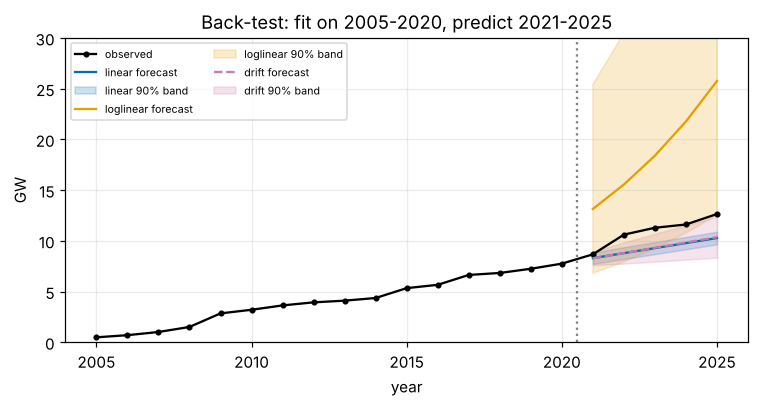

In [5]:
# (a) coverage + scores per model (coverage alone rewards very wide bands)
cover = backtest.assign(abs_err=(backtest["mean"] - backtest["actual"]).abs(),
                        width=backtest["hi"] - backtest["lo"]).groupby("model").agg(
    hits=("inside", "sum"), n=("inside", "count"),
    mean_width=("width", "mean"), MAE=("abs_err", "mean"), interval_score=("IS", "mean"))
cover["coverage"] = cover["hits"] / cover["n"]
print(cover.round(2), "\n")

# (b) how many misses out of 5 are suspicious for a 90% band? X ~ Bin(5, 0.1)
k = np.arange(0, 6)
binom_tab = pd.DataFrame({"misses k": k, "P(X >= k)": stats.binom.sf(k - 1, 5, 0.1)})
print(binom_tab.to_string(index=False))

# plot of the back-test
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.plot(series.year, series.value, "k.-", label="observed")
for m, c, ls in [("linear", "#0072B2", "-"), ("loglinear", "#E69F00", "-"), ("drift", "#CC79A7", "--")]:
    b = backtest[backtest.model == m]
    ax.plot(b.year, b["mean"], color=c, ls=ls, label=f"{m} forecast")
    ax.fill_between(b.year, b.lo, b.hi, color=c, alpha=0.2, label=f"{m} 90% band")
ax.axvline(train.year.max() + 0.5, color="grey", ls=":")
ax.set(xlabel="year", ylabel=f"{UNIT}", ylim=(0, 30), xticks=range(2005, 2026, 5),
       title="Back-test: fit on 2005-2020, predict 2021-2025")
ax.legend(fontsize=7, ncol=2)
plt.tight_layout()
plt.show()

**Your answer (Q2):**

(a) Inside the 90% band, out of 5 held-out years (2021-2025): **linear 1/5**, **log-linear 5/5**, and our naive benchmark **drift** (last value + average of the last 4 yearly changes) **1/5**. But coverage alone is misleading: the log-linear band is 28 GW wide on average and its 2025 median is 25.8 GW for a real 12.6 GW. With the interval score (lower = better) drift is clearly best: **9.6** vs 23.7 for linear and 28.4 for log-linear (MAE 1.65 vs 1.68 vs 7.96 GW).

(b) For X ~ Bin(5, 0.1): P(X ≥ 1) = 0.41, P(X ≥ 2) = 0.08, P(X ≥ 3) = 0.01, P(X ≥ 4) = 0.0005. So already **2 misses** make us doubt a 90% band (less than a 10% chance), and 3 or more is a clear fail. Linear and drift both miss 4 times, because RWE's capacity jumped in 2022 and kept growing faster than before.

(c) We keep the **drift** benchmark. It also wins the rolling back-test: coverage 91% / 80% / 67% at 1 / 2 / 3 years ahead and the best interval score at every horizon (2.9 / 5.0 / 5.6 vs 5.0 / 8.1 / 11.6 for linear and 17.6 / 20.9 / 27.1 for log-linear). The gap between models shows that most of the uncertainty comes from the **model choice**, not from noise. That's why we don't extrapolate a trend to 2030: we build 2030 bottom-up from the pipeline (Part C), and the drift idea only comes back as the "historical pace" scenario (Part D).

## B2. [OPTIONAL] Rolling back-test

Repeat B1 with a **rolling origin**: for every cutoff year from the 10th year onwards, fit on the past and predict 1 to 3 years ahead. Report the coverage by horizon (1, 2, 3 years) for each model. This gives many more test points than a single hold-out.

In [6]:
# rolling origin: fit on all years up to the cutoff, predict 1-3 years ahead
rows = []
for i in range(10, len(series)):                 # first cutoff = 10th year
    tr = series.iloc[:i]
    for m in MODELS:
        pred = fit_predict(tr, 3, m).merge(series, on="year")   # drops years we don't observe
        for h, r in enumerate(pred.itertuples(), start=1):
            rows.append({"model": m, "cutoff": tr.year.max(), "h": h,
                         "inside": r.lo <= r.value <= r.hi,
                         "IS": interval_score(r.value, r.lo, r.hi)})
roll = pd.DataFrame(rows)
roll_cov = roll.pivot_table(index="model", columns="h", values=["inside", "IS"], aggfunc="mean")
roll_cov.columns = [f"{'coverage' if a == 'inside' else 'int. score'} h={h}" for a, h in roll_cov.columns]
print("test points per horizon:", roll[roll.model == "linear"].groupby("h").size().to_dict())
roll_cov.round(2)

test points per horizon: {1: 11, 2: 10, 3: 9}


,int. score h=1,int. score h=2,int. score h=3,coverage h=1,coverage h=2,coverage h=3
model,,,,,,
drift,2.93,5.02,5.55,0.91,0.80,0.67
linear,4.97,8.07,11.63,0.73,0.60,0.56
loglinear,17.55,20.87,27.14,1.00,1.00,0.67


---
# PART C. A range by simulation

Your key quantity is computed from inputs (e.g. capacity x utilisation x emission factor, or emissions x carbon price x pass-through). Pick the **two inputs you are least sure about**.

**Goal.** Fill in `compute_quantity(input1, input2)` with your project formula (vectorised with NumPy), choose a distribution for each input with a **written justification**, and run `n = 5,000` draws for your target year. Report the median and 90% interval. Then run a **one-at-a-time sensitivity**: fix each input at its median in turn and report the relative half-width.

> **Demo.** 2030 emissions = production (Mt) x emission factor (tCO2/t). Production ~ Normal(800, 40); factor ~ Triangular(1.5, 1.85, 2.3).

In [7]:
N = 5_000
TARGET = 2030
LIFE = 25                     # assumed lifetime of a wind/solar unit (years)
now = int(series.year.max())  # 2025 = last complete year in GEM (see Part A checks)
cap_now = series.set_index("year").loc[now, "value"]
H_YEAR = 8.76                 # TWh per GW at 100% load

# ---- capacity factors: (low, mode, high) of a triangular distribution
# wind/solar modes start from UK DUKES 2025 (ch. 6) load factors: onshore 25.0% (2024),
# offshore 36.4% (2025, about the same as 2024), solar 9.2% (UK). RWE's pipeline has a lot of
# Australia / US / Chile solar and new big offshore turbines, so we put the modes a bit higher.
# coal and gas are our own assumptions (lignite baseload but running less since 2023, CCGT mid-merit).
CF_RANGE = {"offshore": (0.33, 0.38, 0.45), "onshore": (0.20, 0.26, 0.33), "solar": (0.09, 0.15, 0.22),
            "coal": (0.40, 0.50, 0.65), "gas": (0.25, 0.40, 0.55)}
CF_MODE = {k: v[1] for k, v in CF_RANGE.items()}
TECH = {"Onshore": "onshore", "Offshore hard mount": "offshore", "Offshore floating": "offshore",
        "Offshore mount unknown": "offshore", "PV": "solar", "Assumed PV": "solar"}

# ---- pipeline that could be online by TARGET (equity GW). GEM has no 'permitted' status
# (permitted projects are inside 'pre-construction'), so the pipeline = announced + pre-construction + construction
pipe = rwe[rwe.Type.isin(RE) & rwe.Status.isin(["construction", "pre-construction", "announced"])
           & ~(rwe["Start year"] > TARGET)].copy()
pipe["grp"] = pipe["Technology"].map(TECH)
assert pipe["grp"].notna().all()
pipe["gw"] = pipe["mw_eq"] / 1000
gw = pipe["gw"].to_numpy()
is_con = (pipe.Status == "construction").to_numpy()
is_pre = (pipe.Status == "pre-construction").to_numpy()
is_ann_off = ((pipe.Status == "announced") & (pipe.grp == "offshore")).to_numpy()
is_ann_ok = ((pipe.Status == "announced") & (pipe.grp != "offshore")).to_numpy()
P_CON = 0.95                  # construction is almost sure to finish by 2030

print(pipe.groupby(["Status", "grp"])["gw"].agg(["count", "sum"]).round(2), "\n")

# old wind/solar that reaches the end of its life by TARGET
old = built.loc[(built["Start year"] <= TARGET - LIFE) & ~(built["Retired year"] <= now), "mw_eq"].sum() / 1000

# ---- fossil capacity to replace (denominator). same rule for coal and gas:
# A (main) = what RWE has committed to close by 2030: its coal exit (lignite agreement with the federal
#   government and NRW, 4 Oct 2022 + RWE's 2030 coal exit target). RWE has NO dated gas exit, it even plans
#   ~3 GW of new H2-ready gas plants, so gas = 0 under this rule.
# B = GEM retirement date <= 2030 for both coal and gas (only 19% of fossil units have a date!)
# C = all operating fossil (coal + gas + oil): upper bound, a full fossil exit
fos = rwe[rwe.Type.isin(FOSSIL) & (rwe.Status == "operating")]
coal, gas = fos[fos.Type == "coal"], fos[fos.Type == "oil/gas"]
DENOM = pd.DataFrame({
    "coal GW": [coal.mw_eq.sum(), coal.loc[coal["Retired year"] <= TARGET, "mw_eq"].sum(), coal.mw_eq.sum()],
    "gas GW": [0.0, gas.loc[gas["Retired year"] <= TARGET, "mw_eq"].sum(), gas.mw_eq.sum()],
}, index=["A. RWE commitment (all coal)", "B. GEM date <= 2030 (coal + gas)", "C. all fossil (coal + gas + oil)"]) / 1000
DENOM["TWh/yr (mode CFs)"] = (DENOM["coal GW"] * CF_MODE["coal"] + DENOM["gas GW"] * CF_MODE["gas"]) * H_YEAR
MAIN = DENOM.index[0]
FOSSIL_TWH = DENOM.loc[MAIN, "TWh/yr (mode CFs)"]
print(DENOM.round(2), "\n")

# ---- priors calibrated on RWE's own track record in GEM
outcome = rwe[rwe.Type.isin(RE)]
done = outcome.Status.isin(["operating", "retired"])
dropped = outcome.Status.str.startswith(("cancelled", "shelved"))
build_mw = outcome.loc[done, "mw_eq"].sum() / outcome.loc[done | dropped, "mw_eq"].sum()  # big projects die more
build_units = done.sum() / (done | dropped).sum()
# timing: of the pre-construction MW that has a planned start year, how much is planned <= TARGET?
pre_all = outcome[(outcome.Status == "pre-construction") & outcome["Start year"].notna()]
t_pre = pre_all.loc[pre_all["Start year"] <= TARGET, "mw_eq"].sum() / pre_all["mw_eq"].sum()
# announced onshore/solar: same question on the whole tracker (RWE has too few dated ones)
ann_all = gipt[(gipt.Status == "announced") & gipt["Start year"].notna()
               & (gipt.Technology.isin(["Onshore", "PV", "Assumed PV"]))]
t_ann = ann_all.loc[ann_all["Start year"] <= TARGET, "Capacity (MW)"].sum() / ann_all["Capacity (MW)"].sum()

# p = P(project gets built) x P(on time | built)
m_pre = build_units * t_pre   # pre-construction is permitted / advanced -> the higher (unit) build rate
m_ann = build_mw * t_ann      # announced is early stage -> the lower (MW) build rate
# announced OFFSHORE: p = 0 by 2030 (no permit yet + 3-4 years of construction after FID)
print(f"RWE build rate: {build_mw:.2f} (MW-weighted) / {build_units:.2f} (per unit); "
      f"on-time share: pre-construction {t_pre:.2f}, announced onshore/solar {t_ann:.2f}")
print(f"-> mean p_pre = {m_pre:.2f}, mean p_ann = {m_ann:.2f}\n")


def beta_from(mean, sd):
    k = mean * (1 - mean) / sd**2 - 1
    return mean * k, (1 - mean) * k


# the two inputs we are least sure about (epistemic): p_pre and p_ann, sd = 0.10 around the data-based means
DIST = {"p_pre": beta_from(m_pre, 0.10), "p_ann": beta_from(m_ann, 0.10)}


def draw_inputs(dist, n=N, seed=SEED):
    g = np.random.default_rng(seed)
    return {k: g.beta(a, b, n) for k, (a, b) in dist.items()}


# common random numbers so that fixing one input does not reshuffle the others
U = np.random.default_rng(SEED + 1).random((N, len(gw)))          # project-level luck (aleatoric)
_g = np.random.default_rng(SEED + 2)
CF_DRAWS = {k: _g.triangular(*v, N) for k, v in CF_RANGE.items()}  # capacity factors
CF_FIXED = {k: np.full(N, v) for k, v in CF_MODE.items()}


def online(p_pre, p_ann, project_level=True):
    """(N, units) matrix: 1 if the unit is online by TARGET. Each project is its own Bernoulli
    with the common probability p of its stage (p = epistemic, Bernoulli = aleatoric)."""
    P = np.zeros((N, len(gw)))
    P[:, is_con] = P_CON
    P[:, is_pre] = np.broadcast_to(p_pre, N)[:, None]
    P[:, is_ann_ok] = np.broadcast_to(p_ann, N)[:, None]
    return (U < P).astype(float) if project_level else P           # expected value if no project luck


def compute_quantity(p_pre, p_ann, project_level=True):
    """RWE wind + solar capacity in TARGET (GW, equity share)."""
    return cap_now - old + online(p_pre, p_ann, project_level) @ gw


def replacement_ratio(p_pre, p_ann, project_level=True, cf=CF_DRAWS, denom=MAIN):
    """Project metric: CF-adjusted pipeline TWh / CF-adjusted fossil TWh to retire."""
    on = online(p_pre, p_ann, project_level)
    unit_cf = np.column_stack([cf[g] for g in pipe.grp])
    add_twh = (on * unit_cf) @ gw * H_YEAR
    fos_twh = (DENOM.loc[denom, "coal GW"] * cf["coal"] + DENOM.loc[denom, "gas GW"] * cf["gas"]) * H_YEAR
    return add_twh / fos_twh


def summary(x):
    q05, q50, q95 = np.percentile(x, [5, 50, 95])
    return pd.Series({"median": q50, "p05": q05, "p95": q95, "width": q95 - q05})


inp = draw_inputs(DIST)
q = compute_quantity(inp["p_pre"], inp["p_ann"])
ratio = replacement_ratio(inp["p_pre"], inp["p_ann"])
print(f"{TARGET} capacity [GW]:", summary(q).round(2).to_dict())
print(f"{TARGET} replacement ratio ({MAIN}):", summary(ratio).round(2).to_dict(),
      f"| P(ratio >= 1) = {(ratio >= 1).mean():.2f}")
print("ratio with the other denominators:",
      {d: round(float(np.median(replacement_ratio(inp['p_pre'], inp['p_ann'], denom=d))), 2) for d in DENOM.index[1:]})

# ---- one-at-a-time sensitivity
def rel_half_width(x):
    s = summary(x)
    return s["width"] / 2 / s["median"]

med = {k: np.median(v) for k, v in inp.items()}
cases = {
    "nothing fixed": dict(p_pre=inp["p_pre"], p_ann=inp["p_ann"]),
    "p_pre fixed": dict(p_pre=med["p_pre"], p_ann=inp["p_ann"]),
    "p_ann fixed": dict(p_pre=inp["p_pre"], p_ann=med["p_ann"]),
    "both p fixed (only project luck left)": dict(p_pre=med["p_pre"], p_ann=med["p_ann"]),
    "no project luck (only p uncertainty)": dict(p_pre=inp["p_pre"], p_ann=inp["p_ann"], project_level=False),
}
sens = pd.DataFrame({
    "capacity rel. half-width": {c: rel_half_width(compute_quantity(**kw)) for c, kw in cases.items()},
    "ratio rel. half-width": {c: rel_half_width(replacement_ratio(**kw)) for c, kw in cases.items()},
})
sens.loc["capacity factors fixed at mode"] = [np.nan, rel_half_width(
    replacement_ratio(inp["p_pre"], inp["p_ann"], cf=CF_FIXED))]
sens["capacity shrink"] = 1 - sens["capacity rel. half-width"] / sens.iloc[0, 0]
sens["ratio shrink"] = 1 - sens["ratio rel. half-width"] / sens.iloc[0, 1]
sens.round(2)

                           count   sum
Status           grp                  
announced        offshore      6  5.99
                 onshore       4  1.96
                 solar         2  0.12
construction     offshore      1  1.40
                 onshore       4  0.40
                 solar         1  0.11
pre-construction offshore     19 12.78
                 onshore      39  3.57
                 solar         6  0.80 

                                  coal GW  gas GW  TWh/yr (mode CFs)
A. RWE commitment (all coal)         7.06    0.00              30.94
B. GEM date <= 2030 (coal + gas)     3.87    1.41              21.90
C. all fossil (coal + gas + oil)     7.06   15.74              86.08 

RWE build rate: 0.42 (MW-weighted) / 0.67 (per unit); on-time share: pre-construction 0.80, announced onshore/solar 0.80
-> mean p_pre = 0.54, mean p_ann = 0.34

2030 capacity [GW]: {'median': 23.88, 'p05': 19.26, 'p95': 28.5, 'width': 9.23}
2030 replacement ratio (A. RWE commitment (all co

,capacity rel. half-width,ratio rel. half-width,capacity shrink,ratio shrink
nothing fixed,0.19,0.46,0.00,0.00
p_pre fixed,0.16,0.39,0.19,0.14
p_ann fixed,0.19,0.45,-0.00,0.00
both p fixed (only project luck left),0.16,0.39,0.20,0.14
no project luck (only p uncertainty),0.12,0.31,0.39,0.31
capacity factors fixed at mode,NaN,0.41,NaN,0.10


### Q3 [QUANT + QUAL] Which input drives the range?

(a) Median and 90% interval for your target year. (b) Which input, once fixed, shrinks the interval most? Is it **aleatoric** or **epistemic**? (c) If you had one more week, what data would you collect to shrink it, and which part of the range would remain whatever you do?

**Your answer (Q3):**

(a) In 2030 RWE's wind + solar capacity has a median of **23.9 GW**, 90% interval **[19.3, 28.5] GW**. Against the coal RWE has committed to close (7.06 GW, 30.9 TWh/yr), that's a replacement ratio of **1.10**, 90% interval [0.63, 1.63], so **P(ratio ≥ 1) = 0.63**. The denominator matters a lot: with GEM retirement dates for coal *and* gas the median would be 1.56, and with all fossil (coal + 15.7 GW of gas) it falls to 0.40. Our first version mixed the rules (all coal but only dated gas, 35.9 TWh); now the same rule applies to both.

(b) Between our two inputs, fixing **p_pre** (pre-construction) shrinks the capacity interval the most (-19%, ratio -14%), while fixing p_ann changes nothing (it only applies to 2.1 GW of onshore/solar). Both p's are **epistemic** (we don't know RWE's real success rate). Splitting the sources shows something bigger, though: with both p fixed, project-level luck (which of the big offshore projects like Norfolk Vanguard 2.8 GW actually make it) still leaves a relative half-width of 0.16, more than p alone (0.12). That part is **aleatoric** from our point of view. Capacity factors add another 10% to the ratio width. Careful: we assume projects are independent, but in reality they share risks (rates, supply chain), so the truth is probably between this and a common-rate version.

(c) With one more week we would check the big pre-construction offshore projects one by one (FID, CfD round won, grid date) and join RWE's own asset register to fix the 64% ownership coverage. What stays whatever we do: weather (year-to-year capacity factors), auction and policy results, and RWE's own investment choices.

---
# PART D. Scenarios

**Goal.** Define at least **two scenarios** relevant to your role (e.g. an NGFS-style orderly vs delayed transition, a carbon price of 50 vs 150 USD/t, 30% of blast furnaces retired). Implement each as a change to the inputs of Part C, rerun the simulation, and create a table `scen` with the median and 90% interval per scenario.

In [8]:
# ---- historical pace: gross additions per start year (what RWE assets really got built each year)
adds = (built.groupby("Start year")["mw_eq"].sum() / 1000).reindex(range(2005, now + 1), fill_value=0)
pace_windows = pd.Series({f"last {w} years": adds.tail(w).mean() for w in [3, 4, 5, 10]})
print("historical build pace (GW/yr, gross):", pace_windows.round(2).to_dict())

# scenario 'Historical pace': instead of the pipeline, RWE keeps building like in 2016-2025.
# we bootstrap 5 future years out of the 10 observed yearly additions -> the spread is empirical
g = np.random.default_rng(SEED + 3)
boot_add = g.choice(adds.tail(10).to_numpy(), size=(N, TARGET - now), replace=True).sum(axis=1)
pipe_cf = np.average(np.column_stack([CF_DRAWS[k] for k in pipe.grp]), axis=1, weights=gw)  # per draw
fos_main = (DENOM.loc[MAIN, "coal GW"] * CF_DRAWS["coal"] + DENOM.loc[MAIN, "gas GW"] * CF_DRAWS["gas"])

base = draw_inputs(DIST)
# 'High delivery' = no project gets cancelled (build rate = 1), only the timing limits stay
high = draw_inputs({"p_pre": beta_from(t_pre, 0.10), "p_ann": beta_from(t_ann, 0.10)})

scen_draws, scen_ratio = {}, {}
scen_draws["Current plan"] = compute_quantity(base["p_pre"], base["p_ann"])
scen_ratio["Current plan"] = replacement_ratio(base["p_pre"], base["p_ann"])
scen_draws["Historical pace"] = cap_now - old + boot_add
scen_ratio["Historical pace"] = boot_add * pipe_cf / fos_main
scen_draws["High delivery"] = compute_quantity(high["p_pre"], high["p_ann"])
scen_ratio["High delivery"] = replacement_ratio(high["p_pre"], high["p_ann"])

# IEA benchmark, pro rata: Net Zero Roadmap (2023) = tripling renewable capacity between 2022 and 2030
IEA_2030 = 3 * series.set_index("year").loc[2022, "value"]

rows = []
for name in scen_draws:
    cap, rat = scen_draws[name], scen_ratio[name]
    rows.append({"scenario": name, **summary(cap).to_dict(),
                 "ratio median": np.median(rat), "ratio p05": np.percentile(rat, 5),
                 "ratio p95": np.percentile(rat, 95), "P(ratio>=1)": (rat >= 1).mean(),
                 "P(cap >= IEA)": (cap >= IEA_2030).mean()})
scen = pd.DataFrame(rows).set_index("scenario")

med_gap = scen["median"].max() - scen["median"].min()
print(f"IEA pro-rata benchmark for {TARGET}: 3 x {IEA_2030 / 3:.2f} = {IEA_2030:.1f} GW")
print(f"largest gap between scenario medians: {med_gap:.2f} GW")
print(f"widest 90% interval inside one scenario: {scen['width'].max():.2f} GW ({scen['width'].idxmax()})")
scen.round(2)

historical build pace (GW/yr, gross): {'last 3 years': 0.69, 'last 4 years': 1.01, 'last 5 years': 1.03, 'last 10 years': 0.78}


IEA pro-rata benchmark for 2030: 3 x 10.61 = 31.8 GW
largest gap between scenario medians: 13.83 GW
widest 90% interval inside one scenario: 9.23 GW (Current plan)


,median,p05,p95,width,ratio median,ratio p05,ratio p95,P(ratio>=1),P(cap >= IEA)
scenario,,,,,,,,,
Current plan,23.88,19.26,28.50,9.23,1.10,0.63,1.63,0.63,0.00
Historical pace,16.04,14.49,18.14,3.65,0.37,0.22,0.59,0.00,0.00
High delivery,29.87,24.51,32.79,8.28,1.64,1.09,2.13,0.97,0.19


### Q4 [QUANT + QUAL] Scenario gap vs interval width

Compare the largest **gap between scenario medians** with the **width** of the interval within one scenario. Which is bigger? What does that mean for how you present your result (one fan chart, or one band per scenario)?

**Your answer (Q4):**

The largest gap between scenario medians is **13.8 GW** (High delivery 29.9 GW vs Historical pace 16.0 GW), while the widest 90% interval inside one scenario is **9.2 GW** (Current plan). So the scenario gap is about 1.5 times the uncertainty inside a scenario: *which* scenario happens matters more than the noise around it. That's why we show **one band per scenario** and not one big fan, otherwise the reader can't see that the answer (ratio ≥ 1 or not) flips with RWE's build speed. The "Historical pace" band (3.7 GW wide) now comes from a bootstrap of RWE's real yearly additions, so its width is based on data. And none of the scenarios reaches the IEA Net Zero pro-rata benchmark (31.8 GW): P = 0.00 / 0.00 / 0.19.

---
## H0 check (project hypothesis)

Our project tests **H0**: the capacity-factor-adjusted replacement ratio is ≥ 1 by 2030, **and** the build rate implied by the pipeline matches what RWE has delivered in the past. We check both parts with the numbers from Parts C and D.

In [9]:
# ---- H0 check: (1) ratio >= 1 by 2030 and (2) implied build rate in line with history
need_new_gw = FOSSIL_TWH / (np.average([CF_MODE[k] for k in pipe.grp], weights=gw) * H_YEAR)
need_cap = cap_now - old + need_new_gw             # capacity in 2030 that gives a ratio of 1
req_pace = need_new_gw / (TARGET - now)            # gross GW per year to build from 2026 to 2030
plan_pace = (np.median(scen_draws["Current plan"]) - cap_now + old) / (TARGET - now)

h0 = pd.Series({
    "new wind/solar needed for ratio = 1 (GW)": need_new_gw,
    "-> capacity needed in 2030 (GW)": need_cap,
    "required build pace 2026-2030 (GW/yr)": req_pace,
    "pace implied by the plan, median (GW/yr)": plan_pace,
    "historical pace, last 10 years (GW/yr)": pace_windows["last 10 years"],
    "historical pace, last 4 years (GW/yr)": pace_windows["last 4 years"],
    "required / historical (10 y)": req_pace / pace_windows["last 10 years"],
    "required / historical (4 y)": req_pace / pace_windows["last 4 years"],
    "P(ratio >= 1), current plan": scen.loc["Current plan", "P(ratio>=1)"],
    "P(ratio >= 1), historical pace": scen.loc["Historical pace", "P(ratio>=1)"],
})
print(h0.round(2).to_string())

new wind/solar needed for ratio = 1 (GW)   10.24
-> capacity needed in 2030 (GW)            22.45
required build pace 2026-2030 (GW/yr)       2.05
pace implied by the plan, median (GW/yr)    2.33
historical pace, last 10 years (GW/yr)      0.78
historical pace, last 4 years (GW/yr)       1.01
required / historical (10 y)                2.61
required / historical (4 y)                 2.03
P(ratio >= 1), current plan                 0.63
P(ratio >= 1), historical pace              0.00


**Conclusion on H0:**

* **Part 1 (ratio ≥ 1):** on paper, roughly yes. The current-plan median is 1.10, but P(ratio ≥ 1) is only 0.63, so it's "about as likely as not" more than a safe yes.
* **Part 2 (build rate): rejected.** To get a ratio of 1, RWE needs about **10.2 GW** of new wind + solar by end 2030, i.e. **2.05 GW per year** from 2026 to 2030 (the pipeline in our current-plan scenario implies 2.3 GW/yr). RWE's assets were commissioned at **0.78 GW/yr** over the last 10 years and **1.01 GW/yr** over the last 4. So RWE has to build **2.0 to 2.6 times faster** than ever before. At its historical pace the ratio is only 0.37 and, in our model, P(ratio ≥ 1) ≈ 0.

So the pipeline covers the coal exit *only if* RWE delivers much faster than its track record, and that is exactly the credibility gap we advise on. (Note: a quick estimate gives (24 − 12.6) / 5 ≈ 2.2 GW/yr; our 2.05 is lower because the corrected denominator only counts the coal RWE has committed to close and uses the pipeline's capacity factor mix.)

---
# PART E. [OPTIONAL] One LLM-extracted variable

If your project uses a variable you could only get from text (targets, ownership shares, plant start dates…):

1. Extract it with an LLM for your companies, using the schema and parser pattern of Lab 5.
2. Label **at least 10** cases by hand (your gold sample).
3. Report accuracy with a **Beta(1,1) 90% interval** and the list of errors by type.

### Q5 [QUANT + QUAL] (optional)

Accuracy with interval, main error type, and one sentence on how the errors could bias your key quantity.

In [10]:
# Part E not done (optional). See the note below for why and what we would extract.

**Why we did not do Part E (optional):** this is our weakest point, so the reason should be clear. Our biggest data problem is ownership: GEM catches only 64% of RWE's reported wind + solar, and some RWE farms are still listed under E.ON. An LLM could help here, by reading RWE's annual report and press releases and extracting for each asset `{name, technology, MW, RWE share, status, COD}`, then checking ≥ 10 cases by hand (Beta(1,1) interval on accuracy). We didn't do it because of time, and because RWE also publishes a *Power Generation Asset Register* as an Excel file. Joining that file directly to GEM would probably be more accurate than LLM extraction, so that's our next step for the paper. If the register is not enough, we would then use the LLM for the assets still missing.

---
# PART F. Communicate

## F1. The figure for your paper

**Goal.** One fan chart: history as a line, then for your target years the median and the **50% and 90%** bands, one colour per scenario (at least the baseline). Label the axes with units, state the scenario in the legend, and save it as `fig_uncertainty.png` for Overleaf.

> **Hint.** Use the Part C/D draws for the target year and widen the bands from today's value to that year, or simulate the path year by year. Do not use a trend that failed the back-test in Part B. `plt.fill_between(...)`.

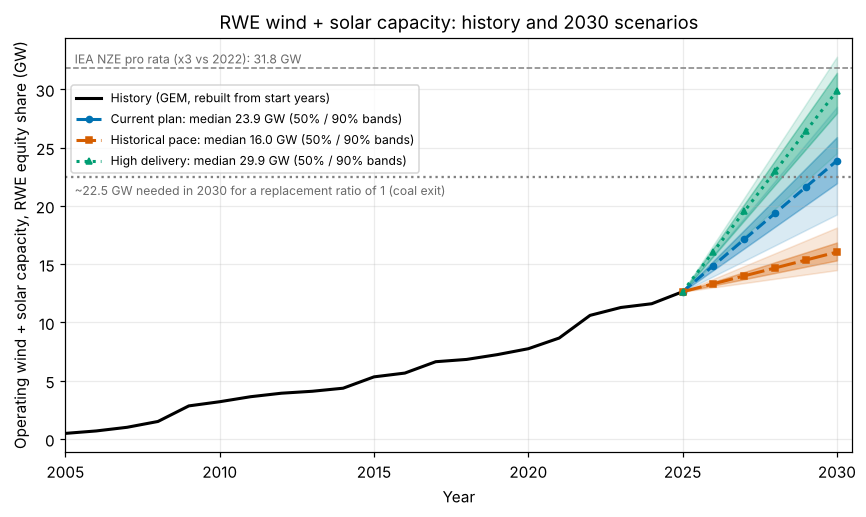

In [11]:
# capacity needed in 2030 for a replacement ratio of 1 = need_cap (computed in the H0 check)
style = {  # colour-blind safe colours (Okabe-Ito) + different line styles and markers
    "Current plan": dict(color="#0072B2", ls="--", marker="o"),
    "Historical pace": dict(color="#D55E00", ls="-.", marker="s"),
    "High delivery": dict(color="#009E73", ls=":", marker="^"),
}
fut_years = np.arange(now, TARGET + 1)
w = (fut_years - now) / (TARGET - now)                   # 0 today -> 1 in the target year

fig, ax = plt.subplots(figsize=(8, 4.8))
ax.plot(series.year, series.value, color="black", lw=2, label="History (GEM, rebuilt from start years)")
for name, draws in scen_draws.items():
    q05, q25, q50, q75, q95 = np.percentile(draws, [5, 25, 50, 75, 95])
    path = lambda qq: cap_now + (qq - cap_now) * w        # widen the band from today's value
    st = style[name]
    ax.fill_between(fut_years, path(q05), path(q95), color=st["color"], alpha=0.15)
    ax.fill_between(fut_years, path(q25), path(q75), color=st["color"], alpha=0.35)
    ax.plot(fut_years, path(q50), color=st["color"], ls=st["ls"], lw=2, marker=st["marker"], ms=4,
            label=f"{name}: median {q50:.1f} GW (50% / 90% bands)")
ax.axhline(need_cap, color="grey", ls=":", lw=1.5)
ax.text(2005.3, need_cap - 0.5, f"~{need_cap:.1f} GW needed in {TARGET} for a replacement ratio of 1 (coal exit)",
        fontsize=8, color="dimgrey", va="top")
ax.axhline(IEA_2030, color="grey", ls="--", lw=1)
ax.text(2005.3, IEA_2030 + 0.4, f"IEA NZE pro rata (x3 vs 2022): {IEA_2030:.1f} GW", fontsize=8, color="dimgrey")
ax.set(xlabel="Year", ylabel="Operating wind + solar capacity, RWE equity share (GW)",
       title=f"RWE wind + solar capacity: history and {TARGET} scenarios", xlim=(2005, TARGET + 0.5))
ax.legend(loc="upper left", fontsize=8, bbox_to_anchor=(0, 0.9))
plt.tight_layout()
fig.savefig("fig_uncertainty.png", dpi=200, bbox_inches="tight")
plt.show()

## F2. The paragraph for your paper

### Q6 [QUAL] About 120 words

Write the **uncertainty and limitations** paragraph of your Overleaf paper. Include: the scenario and horizon, the median and 90% interval, the back-test result (how many held-out years fell inside), the input that drives the range, the largest **scenario** gap, and one limitation of your method. Use one calibrated word from the IPCC scale.

### Q7 [QUAL] One sentence for your slides

Finish this sentence for your role's value proposal: *"Because the range is this wide, the decision that changes is …"*

**Your answer (Q6):**

Under RWE's current pipeline, we estimate its wind and solar capacity at 23.9 GW in 2030 (90% interval 19.3–28.5 GW), a replacement ratio of 1.10 (0.63–1.63) against the coal it committed to close, so P(ratio ≥ 1) = 0.63. Trend models failed our back-test: the linear band caught only 1 of 5 held-out years (2021–2025). The range is mostly driven by which large offshore projects come online in time. The scenario gap is bigger: at its historical pace (0.8–1.0 GW/yr, versus 2.05 needed), RWE reaches 16.0 GW and a ratio of 0.37, so in our model covering the coal exit becomes exceptionally unlikely. Limitations: GEM captures only 64% of RWE's reported capacity, and our history projects today's portfolio backwards.

**Your answer (Q7):**

"Because the range is this wide, the decision that changes is whether we call RWE's coal exit 'covered': we would only say yes if RWE shows it can commission about 2 GW of wind and solar a year (10.2 GW by 2030, 2 to 2.6 times its past pace), so investors should track delivery of the big offshore projects instead of trusting the headline pipeline." 